# ¿Cómo se distribuyen los titulares de La República entre cuatro temas?

**Fecha de descarga:** 17 de octubre de 2026, 09:31 (hora de Perú, UTC−5). **Opción A:** La República.

**URLs base:** https://larepublica.pe/robots.txt, https://larepublica.pe/rss/politica.xml,
https://larepublica.pe/rss/economia.xml, https://larepublica.pe/rss/deportes.xml,
https://larepublica.pe/rss/ciencia.xml; sitemaps y secciones públicas de política, economía,
deportes, ciencia y tecnología. Los enlaces relacionados del propio medio amplían el período.

Meta: 400 noticias reales (~100 por categoría). La muestra tiene cuotas y depende de los enlaces
accesibles: no estima la proporción natural de temas publicada por el periódico.

## 1. Configuración y recolección

El código de recolección está completo en las celdas siguientes. Se consulta robots.txt,
se identifica el uso académico y se espera 1,5–2 segundos entre solicitudes, con máximo
un reintento. Las respuestas XML/HTML y el registro de solicitudes se guardan en `datos/raw/`.

La descarga original del 17 de octubre se conserva como respaldo. `RECOLECTAR = False`
la reutiliza para que el análisis sea reproducible sin consultar otra vez el sitio.
`True` permite ejecutar el recolector; una nueva muestra debe tratarse como otro experimento.
Las correcciones humanas se aplican después, sin modificar el test reservado.

In [1]:
"""Recolección pausada, comprobable y reanudable de La República."""


from collections import Counter
from datetime import datetime, timedelta, timezone
from difflib import SequenceMatcher
from email.utils import parsedate_to_datetime
import gzip
import hashlib
import json
import os
from pathlib import Path
import random
import re
import time
import unicodedata
from urllib.parse import urljoin, urlsplit, urlunsplit
import xml.etree.ElementTree as ET

from bs4 import BeautifulSoup
import pandas as pd
from protego import Protego
import requests

ROOT = Path.cwd()
if not (ROOT / 'datos').exists():
    ROOT = ROOT / 'tarea_1'
assert (ROOT / 'datos').exists(), 'Abrir el proyecto python_intermedio o su carpeta tarea_1'
os.chdir(ROOT)
RAW = ROOT / 'datos/raw'
evidencia = json.loads((RAW / 'recoleccion.json').read_text(encoding='utf-8'))
PERU = timezone(timedelta(hours=-5))
BASE = "https://larepublica.pe"
USER_AGENT = "QLAB-Noticias-Student/1.0 (+https://github.com/bocchienjoyer/python_intermedio)"
COLUMNS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
SECTION_MAP = {
    "politica": "politica",
    "economia": "economia",
    "deportes": "deportes",
    "ciencia": "ciencia_tecnologia",
    "tecnologia": "ciencia_tecnologia",
}
CATEGORIES = list(dict.fromkeys(SECTION_MAP.values()))

### Funciones para normalizar textos y URLs

In [2]:
def now() -> str:
    return datetime.now(PERU).isoformat(timespec="seconds")

def clean_text(value) -> str:
    return " ".join(BeautifulSoup(str(value or ""), "html.parser").get_text(" ").split())

def canonical(url: str) -> str:
    parts = urlsplit(urljoin(BASE, url.strip()))
    return urlunsplit(("https", parts.netloc.lower(), parts.path.rstrip("/"), "", ""))

def section_key(url: str) -> str:
    return urlsplit(url).path.strip("/").split("/")[0]

def title_key(title: str) -> str:
    return re.sub(r"[^\w\s]", "", unicodedata.normalize("NFKC", title).casefold()).strip()

### Acceso respetuoso, respaldo y caché

In [3]:
class PoliteClient:
    """Una solicitud a la vez, caché local y robots RFC 9309 con comodines."""

    def __init__(self, root: Path = ROOT, offline: bool = False):
        self.raw = root / "datos" / "raw"
        self.raw.mkdir(parents=True, exist_ok=True)
        self.session = requests.Session()
        self.session.headers.update({"User-Agent": USER_AGENT})
        self.offline = offline
        self.last_request = 0.0
        self.robots = None
        self.events = []
        self.manifest = self.raw / "solicitudes.jsonl"
        robots = self.get(BASE + "/robots.txt", bootstrap=True)
        self.robots = Protego.parse(robots.decode("utf-8", errors="replace"))

    def log(self, event):
        self.events.append(event)
        with self.manifest.open("a", encoding="utf-8") as stream:
            stream.write(json.dumps(event, ensure_ascii=False) + "\n")

    def get(self, url: str, bootstrap: bool = False, _redirects: int = 0) -> bytes:
        if _redirects > 5:
            raise ValueError("Demasiadas redirecciones")
        url = canonical(url)
        if urlsplit(url).netloc != "larepublica.pe":
            raise ValueError("Fuera del dominio autorizado: " + url)
        if not bootstrap and not self.robots.can_fetch(url, USER_AGENT):
            self.log({"fecha_descarga": now(), "url": url, "estado": "robots_denegado"})
            raise PermissionError("robots.txt no permite: " + url)
        digest = hashlib.sha256(url.encode()).hexdigest()[:24]
        suffix = ".html.gz" if not url.endswith((".xml", ".txt")) else Path(urlsplit(url).path).suffix
        cache = self.raw / (digest + suffix)
        meta_path = self.raw / (digest + ".meta.json")
        if meta_path.exists():
            metadata = json.loads(meta_path.read_text(encoding="utf-8"))
            if metadata.get('location') and metadata.get('status') in (301, 302, 303, 307, 308):
                return self.get(metadata['location'], bootstrap=bootstrap, _redirects=_redirects + 1)
            if cache.exists() and metadata.get("status") == 200:
                return gzip.decompress(cache.read_bytes()) if suffix.endswith(".gz") else cache.read_bytes()
        if self.offline:
            raise FileNotFoundError("Sin caché, modo offline: " + url)
        for attempt in range(2):  # una solicitud inicial y como máximo un reintento
            pause = max(1.5, self.robots.crawl_delay(USER_AGENT) or 0) if self.robots else 1.5
            time.sleep(max(0, self.last_request + pause + random.uniform(0, 0.5) - time.monotonic()))
            self.last_request = time.monotonic()
            try:
                response = self.session.get(url, timeout=(15, 35), allow_redirects=False)
                self.last_request = time.monotonic()
                event = {"fecha_descarga": now(), "url": url, "status": response.status_code,
                         "intento": attempt + 1, "archivo": cache.name,
                         "content_type": response.headers.get("Content-Type", "")}
                if response.is_redirect:
                    event['location'] = canonical(urljoin(url, response.headers['Location']))
                self.log(event)
                if response.is_redirect:
                    target = event['location']
                    if target == url:
                        raise ValueError("Redirección circular")
                    meta_path.write_text(json.dumps(event, ensure_ascii=False, indent=2), encoding='utf-8')
                    return self.get(target, bootstrap=bootstrap, _redirects=_redirects + 1)
                response.raise_for_status()
                cache.write_bytes(gzip.compress(response.content) if suffix.endswith(".gz") else response.content)
                meta_path.write_text(json.dumps(event, ensure_ascii=False, indent=2), encoding="utf-8")
                return response.content
            except requests.RequestException as error:
                self.last_request = time.monotonic()
                if isinstance(error, requests.HTTPError) and response.status_code not in (429, 500, 502, 503, 504):
                    raise
                if attempt:
                    raise
                # Respetar Retry-After cuando sea numérico, además de la pausa ordinaria.
                wait = response.headers.get("Retry-After", "") if "response" in locals() else ""
                if wait.isdigit():
                    time.sleep(min(int(wait), 60))
        raise RuntimeError("Solicitud no completada")

### Lectura de RSS, sitemaps y metadatos HTML

In [4]:
def rss_items(content: bytes) -> list[dict]:
    items = []
    for item in ET.fromstring(content).findall(".//item"):
        url = canonical(item.findtext("link", ""))
        section = section_key(url)
        if section not in SECTION_MAP:
            continue
        categories = [c for c in item.findall("category") if "/tag/" not in c.get("domain", "")]
        label = clean_text(categories[0].text) if categories else section
        date = parsedate_to_datetime(item.findtext("pubDate", "")).astimezone(PERU).date().isoformat()
        items.append({"titular": clean_text(item.findtext("title")),
                      "bajada": clean_text(item.findtext("description")), "medio": "La Republica",
                      "seccion_original": label, "url": url, "fecha": date,
                      "etiqueta": SECTION_MAP[section], "origen": "rss"})
    return items

def sitemap_items(content: bytes) -> list[str]:
    root = ET.fromstring(content)
    return [canonical(node.text) for node in root.findall("{*}url/{*}loc") if node.text]

def article_links(content: bytes) -> list[str]:
    """Enlaces públicos reales, sin construir paginación ni endpoints internos."""
    links = []
    for anchor in BeautifulSoup(content, "html.parser").find_all("a", href=True):
        link = canonical(anchor["href"])
        if (urlsplit(link).netloc == "larepublica.pe" and section_key(link) in SECTION_MAP
                and re.search(r"/20\d{2}/\d{2}/\d{2}/", link) and link not in links):
            links.append(link)
    return links

def article_metadata(content: bytes, url: str) -> dict:
    soup = BeautifulSoup(content, "html.parser")
    objects = []
    def walk(value):
        if isinstance(value, dict):
            objects.append(value)
            for child in value.values():
                if isinstance(child, (dict, list)):
                    walk(child)
        elif isinstance(value, list):
            for child in value:
                walk(child)
    for script in soup.find_all("script", type="application/ld+json"):
        try:
            walk(json.loads(script.string or script.get_text()))
        except (ValueError, TypeError):
            continue
    articles = [obj for obj in objects if any(t in str(obj.get("@type", "")) for t in ("NewsArticle", "Article", "Reportage"))]
    article = max(articles, key=lambda x: bool(x.get("headline")) + bool(x.get("datePublished")), default={})
    def meta(*names):
        for name in names:
            tag = soup.find("meta", attrs={"property": name}) or soup.find("meta", attrs={"name": name})
            if tag and tag.get("content"):
                return tag["content"]
        return ""
    heading = soup.find("h1")
    title = clean_text(article.get("headline") or meta("og:title") or (heading.get_text() if heading else ""))
    summary = clean_text(article.get("description") or meta("og:description", "description"))
    date = article.get("datePublished") or meta("article:published_time", "datePublished")
    if not date:
        match = re.search(r"/(20\d{2})/(\d{2})/(\d{2})/", url)
        date = "-".join(match.groups()) if match else ""
    if not re.fullmatch(r"\d{4}-\d{2}-\d{2}", str(date)):
        date = pd.to_datetime(date, errors="coerce", utc=True)
        date = date.tz_convert(PERU).date().isoformat() if not pd.isna(date) else ""
    section = article.get("articleSection") or meta("article:section") or section_key(url)
    if isinstance(section, list):
        section = section[0] if section else section_key(url)
    return {"titular": title, "bajada": summary, "medio": "La Republica",
            "seccion_original": clean_text(section), "url": canonical(url), "fecha": date,
            "etiqueta": SECTION_MAP.get(section_key(url), ""), "origen": "html_metadata"}

### Descubrimiento de enlaces y selección de noticias

In [5]:
def discover(client: PoliteClient) -> tuple[list[dict], dict]:
    candidates = {}
    sources = {}
    discovery_discards = []
    for section in ("politica", "economia", "deportes", "ciencia"):
        url = f"{BASE}/rss/{section}.xml"
        rows = rss_items(client.get(url))
        sources[url] = len(rows)
        for row in rows:
            if row["url"] in candidates:
                discovery_discards.append({"url": row["url"], "fuente": url, "motivo": "url_repetida_descubrimiento"})
            candidates[row["url"]] = row
        # Los sitemaps sirven solo para descubrir enlaces, sin rutas de paginación restringidas.
        url = f"{BASE}/sitemap/{section}.xml"
        links = sitemap_items(client.get(url))
        sources[url] = len(links)
        print(json.dumps({"seccion": section, "rss": len(rows), "sitemap": len(links)}, ensure_ascii=False), flush=True)
        for link in links:
            if section_key(link) in SECTION_MAP:
                if link in candidates:
                    discovery_discards.append({"url": link, "fuente": url, "motivo": "url_repetida_descubrimiento"})
                candidates.setdefault(link, {"url": link, "etiqueta": SECTION_MAP[section_key(link)], "origen": "sitemap"})
            else:
                discovery_discards.append({"url": link, "fuente": url, "motivo": "seccion_fuera_de_alcance"})
    for section in SECTION_MAP:
        url = f"{BASE}/{section}"
        links = article_links(client.get(url))
        sources[url] = len(links)
        for link in links:
            candidates.setdefault(link, {"url": link, "etiqueta": SECTION_MAP[section_key(link)],
                                         "origen": "seccion_html", "descubierto_en": url})
    pd.DataFrame(discovery_discards, columns=["url", "fuente", "motivo"]).to_csv(
        RAW / "descartes_descubrimiento.csv", index=False, encoding="utf-8")
    return list(candidates.values()), sources

def collect(per_category: int = 100, offline: bool = False, pilot: bool = False, since: str = "2026-01-01"):
    client = PoliteClient(offline=offline)
    candidates, sources = discover(client)
    out = RAW
    pd.DataFrame(candidates).to_csv(out / "candidatos.csv", index=False, encoding="utf-8")
    counts = Counter()
    rows, discarded, keys, mapping = [], [], [], set()
    known_urls = {row["url"] for row in candidates}
    processed = 0
    for candidate in candidates:
        category = candidate["etiqueta"]
        if counts[category] >= per_category:
            continue
        url = candidate["url"]
        processed += 1
        if processed > 1000:
            break
        try:
            # Incluso en RSS se comprueba el enlace y se respalda su HTML.
            content = client.get(url)
            # Ampliar el período con noticias relacionadas enlazadas por el propio medio.
            # Cada enlace se comprueba con robots antes de solicitarlo; límite global de 1.000 páginas.
            for link in article_links(content):
                if link not in known_urls and len(candidates) < 5000:
                    known_urls.add(link)
                    candidates.append({"url": link, "etiqueta": SECTION_MAP[section_key(link)],
                                       "origen": "enlace_relacionado", "descubierto_en": url})
            row = candidate if candidate.get("titular") and candidate.get("bajada") else article_metadata(content, url)
            if not row.get("titular"):
                raise ValueError("titular_vacio")
            if not row.get("bajada"):
                raise ValueError("bajada_ausente")
            if not row.get("fecha"):
                raise ValueError("fecha_ausente")
            if row["etiqueta"] not in CATEGORIES:
                raise ValueError("fuera_de_categorias")
            if row["fecha"] > datetime.now(PERU).date().isoformat():
                raise ValueError("fecha_futura")
            if row["fecha"] < since:
                raise ValueError("publicacion_anterior_a_" + since)
            key = title_key(row["titular"])
            if key in keys:
                raise ValueError("titular_duplicado")
            if any(SequenceMatcher(None, key, other, autojunk=False).ratio() >= 0.95 for other in keys):
                raise ValueError("titular_casi_duplicado_095")
            mapping.add((section_key(url), row["seccion_original"], row["etiqueta"]))
            rows.append({column: row[column] for column in COLUMNS})
            keys.append(key)
            counts[category] += 1
            if counts[category] % 10 == 0:
                print(json.dumps({"categoria": category, "validas": counts[category], "total": len(rows)}, ensure_ascii=False), flush=True)
        except (requests.RequestException, ValueError, PermissionError, FileNotFoundError) as error:
            discarded.append({"url": url, "titular": candidate.get("titular", ""), "motivo": str(error)})
        if all(counts[c] >= per_category for c in CATEGORIES):
            break
    df = pd.DataFrame(rows, columns=COLUMNS).sort_values(["etiqueta", "fecha", "url"], ascending=[True, False, True])
    filename = "piloto.csv" if pilot else "noticias.csv"
    df.to_csv(out / filename, index=False, encoding="utf-8")
    pd.DataFrame(candidates).to_csv(out / "candidatos.csv", index=False, encoding="utf-8")
    pd.DataFrame(discarded, columns=["url", "titular", "motivo"]).to_csv(out / "descartes.csv", index=False, encoding="utf-8")
    pd.DataFrame(sorted(mapping), columns=["ruta_seccion", "seccion_original", "etiqueta"]).to_csv(out / "mapeo_secciones.csv", index=False, encoding="utf-8")
    summary = {"fecha_descarga": now(), "medio": "La Republica", "opcion": "A", "piloto": pilot,
               "objetivo_por_categoria": per_category, "filas": len(df), "columnas": COLUMNS,
               "fecha_minima_configurada": since,
               "por_categoria": dict(counts), "candidatos_unicos": len(candidates), "fuentes": sources,
               "descartes": dict(Counter(x["motivo"] for x in discarded)),
               "fecha_min": str(df.fecha.min()), "fecha_max": str(df.fecha.max()),
               "url_verificadas_http_200": len(df), "user_agent": USER_AGENT,
               "pausa_segundos": [1.5, 2.0], "max_reintentos": 1,
               "criterio_muestra": "RSS, sitemaps, secciones y enlaces públicos relacionados; cuota por categoría; no es muestra aleatoria del medio."}
    (out / ("resumen_piloto.json" if pilot else "resumen_recoleccion.json")).write_text(
        json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(summary, ensure_ascii=False, indent=2), flush=True)
    if any(counts[c] < per_category for c in CATEGORIES):
        raise RuntimeError("Cobertura insuficiente; revisar fuentes y descartes antes de dar por terminada la recolección.")
    return df, summary

In [6]:
from pathlib import Path
import json
import os
import platform
import pandas as pd
import plotly.express as px
import plotly.io as pio
from IPython.display import display

# Edge permite que Kaleido genere una imagen junto a la figura interactiva.
edge = Path(os.environ.get('PROGRAMFILES(X86)', 'C:/Program Files (x86)')) / 'Microsoft/Edge/Application/msedge.exe'
if edge.exists():
    os.environ.setdefault('BROWSER_PATH', str(edge))
pio.renderers.default = 'plotly_mimetype+png'
pio.templates.default = 'plotly_white'
pd.set_option('display.max_colwidth', None)
print('Python:', platform.python_version())
RECOLECTAR = False
if RECOLECTAR:
    original, resumen = collect(per_category=100)
else:
    original = pd.read_csv(RAW / 'noticias_antes_auditoria.csv', keep_default_na=False)
    resumen = evidencia['resumen']
df = original.copy()
# Los dos casos revisados pertenecen a entrenamiento; validación y test se conservan.
reemplazos = {r['url']: r for r in evidencia['reemplazos']}
for correccion in evidencia['correcciones_auditoria']:
    nueva = reemplazos[correccion['url_reemplazo']]
    df.loc[df.url == correccion['url_descartada'], COLUMNS] = [nueva[c] for c in COLUMNS]
display(pd.DataFrame({'indicador': ['Noticias finales', 'Enlaces candidatos únicos', 'URLs finales con HTTP 200'],
                      'valor': [len(df), resumen['candidatos_unicos'], resumen['url_verificadas_http_200']]}))
display(pd.DataFrame(list(resumen['fuentes'].items()), columns=['fuente', 'entradas_descubiertas']))
urls = pd.DataFrame(evidencia['verificacion_urls'])
assert set(urls.url) == set(df.url) and urls.http_final.eq(200).all()
print('URLs con respuesta final HTTP 200:', len(urls), '· Con redirección:', int(urls.redirige.sum()))
display(urls[urls.redirige])

Python: 3.13.5


,indicador,valor
0,Noticias finales,400
1,Enlaces candidatos únicos,2269
2,URLs finales con HTTP 200,400


,fuente,entradas_descubiertas
0,https://larepublica.pe/rss/politica.xml,26
1,https://larepublica.pe/sitemap/politica.xml,26
2,https://larepublica.pe/rss/economia.xml,14
3,https://larepublica.pe/sitemap/economia.xml,14
4,https://larepublica.pe/rss/deportes.xml,13
5,https://larepublica.pe/sitemap/deportes.xml,13
6,https://larepublica.pe/rss/ciencia.xml,7
7,https://larepublica.pe/sitemap/ciencia.xml,7
8,https://larepublica.pe/politica,17
9,https://larepublica.pe/economia,19


URLs con respuesta final HTTP 200: 400 · Con redirección: 1


,url,url_final,http_final,redirige,fecha_verificacion
91,https://larepublica.pe/tecnologia/2025/10/14/google-discover-asi-puedes-seguir-a-la-republica-desde-la-app-y-recibir-todas-sus-noticias-en-tu-celular-atmp-1338218,https://larepublica.pe/tecnologia/2026/03/16/google-discover-como-seguir-a-la-republica-desde-tu-celular-y-recibir-sus-noticias-al-instante-873552,200,True,2026-10-17T09:07:37-05:00


## 2. Limpieza, equivalencias y descartes

La categoría de referencia procede de la sección de origen. Ciencia y tecnología se agrupan
en `ciencia_tecnologia`; no se crea una quinta clase. Se conserva el nombre original de sección.
La tabla incluye la ruta para desambiguar nombres de subsección que podrían repetirse.

Se eliminan URLs repetidas durante el descubrimiento y titulares vacíos, duplicados o casi
idénticos (similitud de caracteres ≥ 0,95). La bajada procede de RSS o metadatos HTML, nunca
de generación artificial. Los errores y descartes se guardan con motivo; los candidatos que no
se descargan porque la cuota ya está completa no se presentan como noticias recolectadas.

El filtro de publicaciones desde el 1 de enero de 2026 es una decisión para delimitar nuestra muestra; la consigna no obliga a ese período. Las 60 referencias repetidas al combinar fuentes se registran aparte de los 117 descartes de extracción y revisión humana.

In [7]:
mapeo = pd.DataFrame(evidencia['mapeo_secciones'])
display(mapeo)
print('Regla explícita por ruta:', SECTION_MAP)
descartes = pd.DataFrame(evidencia['descartes'])
descubrimiento = pd.DataFrame(evidencia['descartes_descubrimiento'])
print('Descartes de extracción y revisión humana:', len(descartes))
motivos_legibles = {
    'publicacion_anterior_a_2026-01-01': 'Publicación anterior al 1 de enero de 2026',
    'titular_casi_duplicado_095': 'Titular casi duplicado (similitud de al menos 95%)',
    'titular_duplicado': 'Titular duplicado',
    'auditoria_humana_fuera_de_alcance': 'Fuera de alcance según la revisión humana'
}
resumen_descartes = descartes.assign(
    motivo=descartes.motivo.str.replace(r'^404 .*', 'Enlace no encontrado (HTTP 404)', regex=True).replace(motivos_legibles)
).groupby('motivo').size().rename('cantidad').reset_index()
display(resumen_descartes)
print('Referencias repetidas al combinar las fuentes:', len(descubrimiento))
display(descubrimiento.assign(motivo=descubrimiento.motivo.replace({'url_repetida_descubrimiento': 'URL repetida al combinar fuentes'})).groupby('motivo').size().rename('cantidad').reset_index())
controles = pd.DataFrame({
    'control': ['Siete columnas exactas', '350 o más noticias', 'Cuatro categorías oficiales',
                'Sin URLs duplicadas', 'Sin titulares vacíos', 'Sin bajadas vacías', 'Mapeo consistente con ruta'],
    'cumple': [list(df.columns) == COLUMNS, len(df) >= 350, set(df.etiqueta) == set(CATEGORIES),
               not df.url.duplicated().any(), df.titular.str.strip().ne('').all(),
               df.bajada.str.strip().ne('').all(),
               df.apply(lambda r: SECTION_MAP.get(section_key(r.url)) == r.etiqueta, axis=1).all()]})
display(controles)
assert controles.cumple.all(), 'Revisar controles fallidos antes de modelar'

,ruta_seccion,seccion_original,etiqueta
0,ciencia,Ciencia,ciencia_tecnologia
1,deportes,Deportes,deportes
2,economia,Economía,economia
3,economia,Precio del dólar,economia
4,politica,Política,politica
5,tecnologia,Tecnología,ciencia_tecnologia


Regla explícita por ruta: {'politica': 'politica', 'economia': 'economia', 'deportes': 'deportes', 'ciencia': 'ciencia_tecnologia', 'tecnologia': 'ciencia_tecnologia'}
Descartes de extracción y revisión humana: 117


,motivo,cantidad
0,Enlace no encontrado (HTTP 404),1
1,Fuera de alcance según la revisión humana,2
2,Publicación anterior al 1 de enero de 2026,98
3,Titular casi duplicado (similitud de al menos 95%),13
4,Titular duplicado,3


Referencias repetidas al combinar las fuentes: 60


,motivo,cantidad
0,URL repetida al combinar fuentes,60


,control,cumple
0,Siete columnas exactas,True
1,350 o más noticias,True
2,Cuatro categorías oficiales,True
3,Sin URLs duplicadas,True
4,Sin titulares vacíos,True
5,Sin bajadas vacías,True
6,Mapeo consistente con ruta,True


### Revisión de noticias fuera de alcance

Durante la revisión manual descarté dos noticias cuyo tema principal consideré fuera de las
cuatro categorías: un hallazgo arqueológico centrado en la historia de un lugar y el accidente
de un alcalde. Se sustituyeron por noticias de las mismas categorías para conservar las 400 filas.

Ambos casos pertenecían al conjunto de entrenamiento. Las noticias de validación y test no
cambiaron. La muestra auditada y el cálculo del acuerdo con el LLM se presentan en
`02_clasificacion.ipynb`. El respaldo `datos/raw/noticias_antes_auditoria.csv` conserva la selección
anterior a estas sustituciones.

In [8]:
correcciones = pd.DataFrame(evidencia['correcciones_auditoria'])
display(correcciones[['caso', 'titular_descartado', 'motivo_humano', 'particion', 'titular_reemplazo', 'url_reemplazo']])
assert correcciones.particion.eq('train').all()
assert set(correcciones.url_reemplazo).issubset(set(df.url))
assert not set(correcciones.url_descartada).intersection(df.url)

,caso,titular_descartado,motivo_humano,particion,titular_reemplazo,url_reemplazo
0,10,"Casi 2.000 años bajo tierra: arqueólogos encuentran el lugar donde un dios romano ""impactó"" con un rayo la Villa de Adriano",Lo considero un tema histórico fuera del alcance de las cuatro categorías.,train,Astrónomos detectan el azúcar de las frambuesas en el centro de la Vía Láctea que ayudaría a explicar el origen de la vida,https://larepublica.pe/ciencia/2026/07/14/astronomos-detectan-el-azucar-de-las-frambuesas-en-el-centro-de-la-via-lactea-que-ayudaria-a-explicar-el-origen-de-la-vida-1162392
1,19,Puno: alcalde de Quiaca muere tras caer a un barranco con la camioneta que conducía con destino Juliaca,El tema principal es un accidente; la mención del alcalde no lo convierte en una noticia política.,train,Ernesto Zunini advierte que pedido de facultades busca debilitar a Diputados: “Para que se gobierne desde el Senado”,https://larepublica.pe/politica/2026/10/01/ernesto-zunini-advierte-que-pedido-de-facultades-busca-debilitar-a-diputados-para-que-se-gobierne-desde-el-senado-69813


## 3. Análisis exploratorio con Plotly Express

Las figuras conservan su salida interactiva y una imagen estática para la lectura en GitHub.
Los títulos se calculan a partir de los datos. La distribución por categoría refleja una decisión
de muestreo por cuotas, no una conclusión sobre la agenda editorial del medio.

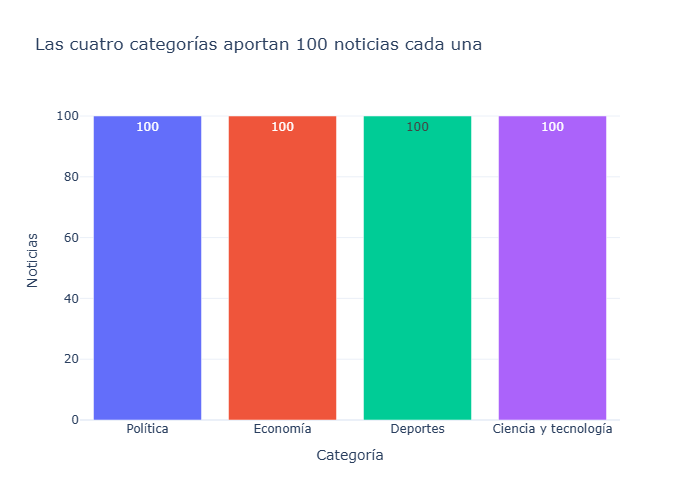

In [9]:
por_categoria = df.etiqueta.value_counts().reindex(CATEGORIES).rename_axis('categoria').reset_index(name='noticias')
nombres = {'politica': 'Política', 'economia': 'Economía', 'deportes': 'Deportes',
           'ciencia_tecnologia': 'Ciencia y tecnología'}
por_categoria['categoria_visible'] = por_categoria.categoria.map(nombres)
titulo = ('Las cuatro categorías aportan ' + str(int(por_categoria.noticias.iloc[0])) + ' noticias cada una'
          if por_categoria.noticias.nunique() == 1 else 'La muestra tiene diferencias de tamaño entre categorías')
fig = px.bar(por_categoria, x='categoria_visible', y='noticias', color='categoria_visible',
             title=titulo, text_auto=True, labels={'categoria_visible': 'Categoría', 'noticias': 'Noticias'})
fig.update_layout(showlegend=False)
fig.show()

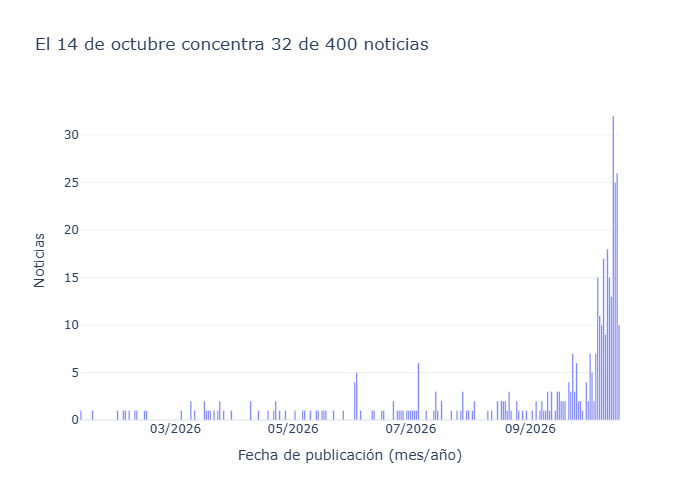

Período de publicación: del 11/01/2026 al 17/10/2026


In [10]:
por_fecha = df.groupby('fecha').size().rename('noticias').reset_index().sort_values('fecha')
por_fecha['fecha'] = pd.to_datetime(por_fecha.fecha)
pico = por_fecha.loc[por_fecha.noticias.idxmax()]
meses = ['enero', 'febrero', 'marzo', 'abril', 'mayo', 'junio',
         'julio', 'agosto', 'septiembre', 'octubre', 'noviembre', 'diciembre']
fecha_pico = f"{pico['fecha'].day} de {meses[pico['fecha'].month - 1]}"
fig = px.bar(por_fecha, x='fecha', y='noticias',
             title=f"El {fecha_pico} concentra {int(pico['noticias'])} de {len(df)} noticias",
             labels={'fecha': 'Fecha de publicación (mes/año)', 'noticias': 'Noticias'})
fig.update_xaxes(dtick='M2', tickformat='%m/%Y')
fig.show()
fecha_inicio = pd.to_datetime(df.fecha.min()).strftime('%d/%m/%Y')
fecha_fin = pd.to_datetime(df.fecha.max()).strftime('%d/%m/%Y')
print(f'Período de publicación: del {fecha_inicio} al {fecha_fin}')

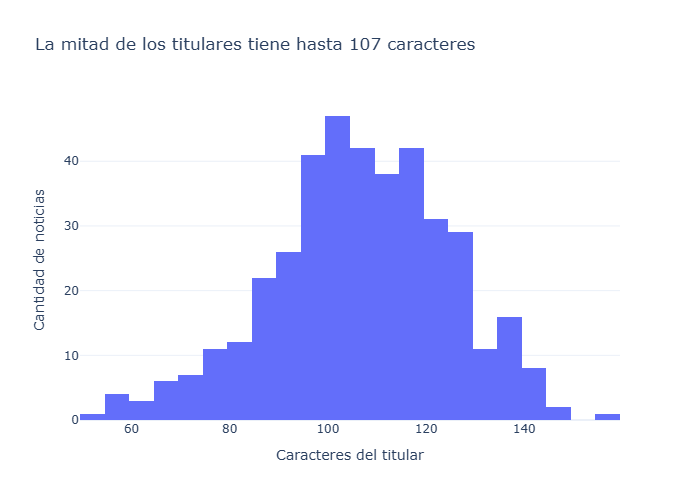

,caracteres
count,400.000000
mean,106.672500
std,18.364869
min,53.000000
25%,96.000000
50%,107.000000
75%,119.000000
max,158.000000


In [11]:
longitud = df.titular.str.len()
fig = px.histogram(x=longitud, nbins=25,
                   title=f'La mitad de los titulares tiene hasta {longitud.median():.0f} caracteres',
                   labels={'x': 'Caracteres del titular', 'y': 'Cantidad de noticias'})
fig.update_layout(yaxis_title='Cantidad de noticias')
fig.show()
display(longitud.describe().rename('caracteres').to_frame())

## 4. Validación de los extremos

Los ejemplos permiten comprobar si los valores extremos del histograma son titulares reales
y no errores de extracción. Se muestran sus enlaces y longitudes exactas.

In [12]:
extremos = df.assign(caracteres=df.titular.str.len())
print('Cinco titulares más cortos:')
display(extremos.nsmallest(5, 'caracteres')[['titular', 'caracteres', 'etiqueta', 'url']])
print('Cinco titulares más largos:')
display(extremos.nlargest(5, 'caracteres')[['titular', 'caracteres', 'etiqueta', 'url']])

Cinco titulares más cortos:


,titular,caracteres,etiqueta,url
288,Movistar: Más de 100 comunidades rurales acceden a 4G,53,economia,https://larepublica.pe/economia/2026/05/14/movistar-mas-de-100-comunidades-rurales-acceden-a-4g-hnews-987770
122,¿Cuándo inicia la Liga Peruana de Vóley Femenina 2026-27?,57,deportes,https://larepublica.pe/deportes/2026/10/13/cuando-inicia-la-liga-peruana-de-voley-femenino-202627-423826
376,Hackean cuenta de X del Ministerio de Economía y Finanzas,57,politica,https://larepublica.pe/politica/2026/09/14/hackean-cuenta-de-x-del-ministerio-de-economia-y-finanzas-hnews-992502
352,JNE deberá resolver 21 casos de reeleción inconstitucional,58,politica,https://larepublica.pe/politica/2026/10/09/elecciones-regionales-jne-debera-resolver-21-casos-de-reelecion-inconstitucional-hnews-713709
360,Pugnas políticas entre militantes de Fuerza Popular en Puno,59,politica,https://larepublica.pe/politica/2026/10/09/pugnas-politicas-entre-militantes-de-fuerza-popular-en-puno-hnews-740934


Cinco titulares más largos:


,titular,caracteres,etiqueta,url
44,"La humanidad roza sus límites: la población mundial alcanzaría los 12.400 millones en 2070, mientras científicos sugieren reducirla a 4.000 millones para 2200",158,ciencia_tecnologia,https://larepublica.pe/ciencia/2026/09/30/la-humanidad-roza-sus-limites-la-poblacion-mundial-alcanzaria-los-12400-millones-en-2070-mientras-cientificos-sugieren-reducirla-a-4000-millones-para-2200-838170
21,"Australia recuperó sus praderas marinas tras un ciclón y grandes inundaciones, pero los científicos descubrieron que los peces ya no eran los mismos",148,ciencia_tecnologia,https://larepublica.pe/ciencia/2026/10/12/australia-recupero-sus-praderas-marinas-tras-un-ciclon-y-grandes-inundaciones-pero-los-cientificos-descubrieron-que-los-peces-ya-no-eran-los-mismos-126384
104,"Mia Shalit, arquera de Universitario, destaca el nivel de las cremas pese a derrota ante Palmeiras por Copa Libertadores Femenina: ""Estuvimos cerca""",148,deportes,https://larepublica.pe/deportes/2026/10/16/mia-shalit-arquera-de-universitario-destaca-el-nivel-de-las-cremas-pese-a-derrota-ante-palmeiras-por-copa-libertadores-femenina-estuvimos-cerca-600528
19,"Un efecto visto en ‘Dragon Ball’, pero con insectos: moscas de frutas entrenadas con gravedad extrema se vuelven más resistentes e hiperactivas",143,ciencia_tecnologia,https://larepublica.pe/ciencia/2026/10/14/un-efecto-visto-en-dragon-ball-pero-con-insectos-moscas-de-frutas-entrenadas-con-gravedad-extrema-se-vuelven-mas-resistentes-e-hiperactivas-901600
57,"El mayor volcán del sistema solar casi triplica la altura del Everest en la Tierra: creció sin placas tectónicas, aunque su planeta sí tiembla",142,ciencia_tecnologia,https://larepublica.pe/ciencia/2026/08/31/el-volcan-mas-grande-del-sistema-solar-casi-triplica-al-everest-crecio-sin-placas-tectonicas-aunque-en-su-planeta-si-ocurren-sismos-2979255


## 5. Exportación y límites

Se guardan exactamente las siete columnas requeridas. La muestra tiene cuotas, procede de un
solo medio y depende de los enlaces accesibles. Las secciones editoriales pueden mezclar temas.
Los respaldos y decisiones de limpieza se conservan en `datos/raw/`; sus tablas relevantes se
muestran arriba. La disponibilidad futura de una URL puede cambiar.

In [13]:
assert len(df) == 400 and df.etiqueta.value_counts().eq(100).all()
df[COLUMNS].to_csv('datos/noticias.csv', index=False, encoding='utf-8')
print('df.shape =', df.shape)
display(df.head(5))

df.shape = (400, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Científicos descubren una nueva especie de flor albiceleste en los andes peruanos y la nombraron en honor a Lionel Messi,"El color de los pétalos evoca la camiseta de la selección de fútbol, que vistió el famoso futbolista argentino.",La Republica,Ciencia,https://larepublica.pe/ciencia/2026/10/16/cientificos-descubren-una-nueva-especie-de-flor-albiceleste-en-los-andes-peruanos-y-la-nombraron-en-honor-a-lionel-messi-1575520,2026-10-16,ciencia_tecnologia
1,"El sistema solar se desintegraría mucho antes de lo previsto: después de todo, Newton se equivocó",Los planetas más grandes podrían entrar en un caos orbital mucho antes de la muerte de nuestra estrella.,La Republica,Ciencia,https://larepublica.pe/ciencia/2026/10/16/el-sistema-solar-se-desintegraria-mucho-antes-de-lo-previsto-despues-de-todo-newton-se-equivoco-1090320,2026-10-16,ciencia_tecnologia
2,"La Antártida se encuentra cubierta de hielo de hasta 4 km de espesor, pero no se compara en nada con lo que orbita cerca de Júpiter",Las mediciones brindan información sobre un mundo congelado que albergaría un océano líquido oculto bajo la enorme capa de hielo.,La Republica,Ciencia,https://larepublica.pe/ciencia/2026/10/16/la-antartida-se-encuentra-cubierta-de-hielo-de-hasta-4-km-de-espesor-pero-no-se-compara-en-nada-con-lo-que-orbita-cerca-de-jupiter-667888,2026-10-16,ciencia_tecnologia
3,Un estudio científico advierte sobre las bolsas de té: algunas liberan miles de millones de partículas de plástico durante la preparación,"El estudio plantea preguntas sobre los efectos de los microplásticos en la salud, aunque no se establece un vínculo directo con enfermedades.",La Republica,Ciencia,https://larepublica.pe/ciencia/2026/10/16/un-estudio-cientifico-advierte-sobre-las-bolsas-de-te-algunas-liberan-miles-de-millones-de-particulas-de-plastico-durante-la-preparacion-996375,2026-10-16,ciencia_tecnologia
4,Un lagarto de la época de los dinosaurios perdió su cola hace 99 millones de años y el ámbar conservó la evidencia,El fósil demuestra que este mecanismo de defensa ya estaba presente en estos reptiles del Cretácico medio.,La Republica,Ciencia,https://larepublica.pe/ciencia/2026/10/16/un-lagarto-de-la-epoca-de-los-dinosaurios-perdio-su-cola-hace-99-millones-de-anos-y-el-ambar-conservo-la-evidencia-1288416,2026-10-16,ciencia_tecnologia
